<!-- d2l:prose id=rag-failures-md-1 fw=all -->

# Failures and Fixes in Retrieval-Augmented Generation

Suppose you have built the pipeline of that section and are looking
at the 26 `dev` questions it gets wrong. The natural impulse is to start
fixing. Most people who build such systems have a favorite repair: smaller
chunks, a rewritten query, more passages in the prompt, a sterner
instruction to the generator. Each is plausible, and each has a paper that
reports a gain. Yet this baseline already puts a relevant chunk into the
context for 213 of the 220 answerable questions, and the wrong answer that
opened that section had its passage ranked first. Which of the
favorites can help a system like that, and how would we know?

In this section the measurements choose. We change one stage at a time and
compare with the baseline on the same questions. We sort the wrong answers
by the first stage that lost them. And we test the repair of the largest
class, written down before any failure was counted, on the 240 `test`
questions, read once. None of this is new: medicine has run its clinical
trials this way for decades, with a control measured on the same patients
and an analysis fixed before the data come in. Here the procedure will
matter more than any of the repairs. A short derivation then asks whether
the answers alone could teach the retriever which passages the generator
can use. The section ends on the question that longer context windows keep
raising: is retrieval needed at all when whole chapters fit into the
prompt?

The first cells load what that section built: its configurations,
the corpus with its two retrievers, the recorded answers with the judge's
verdicts, and the library's helpers for paired intervals. They hold no new
idea, and a first reading can skip to that section. As
there, a normal run replays the recorded answers and verdicts, and
`D2L_RERUN` regenerates them.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import json
import os
import pandas as pd
import random
import re
import textwrap
import time
import transformers
import warnings

In [3]:
# The settings of the previous section: reading its records checks them
d2l.HF_REVISIONS['Qwen/Qwen3.5-9B'] = (  # pinned in the notebook, as there
    'c202236235762e1c871ad0ccb60c8ee5ba337b9a')
GEN, RERANKER = d2l.RAG_GENERATOR, d2l.RAG_RERANKER
EMB = d2l.DEFAULT_EMBEDDER
REV = {GEN: d2l.HF_REVISIONS[GEN],
       **{m: d2l.HF_ENCODER_REVISIONS[m] for m in (EMB, RERANKER)}}
GPU = torch.cuda.is_available()
ARTIFACTS, CONFIGS = d2l.RAG_ARTIFACTS, d2l.RAG_CONFIGS
BASE, STAGES, CONTROLS = d2l.RAG_BASE, d2l.RAG_STAGES, d2l.RAG_CONTROLS
RERUN = d2l._rag_rerun()  # here: rag-cards, -gen-stages, -gen-fix
assert GPU or not RERUN - {'rag-cards'}, 'answers need a GPU'
K, BUDGET, DEPTH = BASE['k'], BASE['budget'], 50  # passages; tokens; ranking
BATCH = BASE['batch']  # prompts per batch
QUICK = False  # True: 80 stratified dev and test items (development only)
assert not (QUICK and RERUN), 'QUICK results are never saved'
CONCURRENCY, N_CARDS = 8, 50  # requests in flight when judged; cards
CARD_GIB = 21.5  # estimates; measured peaks add 0.4-1.5 (23.6 GiB usable)

In [4]:
QA = {s: d2l.book_qa(s) for s in ('train', 'dev', 'test')}  # test: once
DEV, TEST = (QA[s].subset(80) if QUICK else QA[s] for s in ('dev', 'test'))
ITEMS = {q['qid']: q for qa in QA.values() for q in qa}
CORPUS = d2l.book_corpus()  # structure-aware chunks of at most 512 tokens
FIXED = d2l.book_corpus('fixed', size=256, overlap=64)
RET = {'sections': d2l.BookRetriever(CORPUS, reranker=RERANKER),
       'fixed': d2l.BookRetriever(FIXED, reranker=RERANKER)}
CHUNKS = {c['id']: c for R in RET.values() for c in R.corpus.chunks}
CLUSTER = d2l._rag_clusters(ITEMS.values(), CORPUS)  # qid: its document
mem = lambda m, n, b: d2l.config_memory(transformers.AutoConfig
                                        .from_pretrained(m, revision=REV[m]),
                                        n, b)
g, e, r = mem(GEN, 3300, BATCH), mem(EMB, 512, 16), mem(RERANKER, 1024, 16)
KEEP_GEN = (g['weights'] + e['weights'] + r['weights'] + max(
    e['activations'], r['activations'])) / 2**30 < CARD_GIB
print(f'{len(DEV)} dev and {len(TEST)} test questions; {len(CORPUS):,} '
      f'section chunks and {len(FIXED):,} windows')

240 dev and 240 test questions; 5,324 section chunks and 9,447 windows


In [5]:
GENS = d2l._rag_load_gens(RERUN)  # the answers and their verdicts
JUD = d2l._rag_load_judgments(d2l._rag_run_path('rag-judge', RERUN))
boot, ci, paired = d2l._rag_boot, d2l._rag_ci, d2l._rag_paired
scores = lambda c, split='dev': d2l._rag_scores(  # per-question scores
    c, split, GENS, JUD, RET, ITEMS, CLUSTER, CONCURRENCY)
ready = lambda *c, split='dev': d2l._rag_ready(  # are all of c's verdicts in?
    c, split, GENS, JUD, RERUN, CONCURRENCY)
S = {'base': scores('base')} if ready('base') else {}
print(f'{len(GENS):,} recorded answers in {GENS.config.nunique()} '
      f'configurations, {len(JUD):,} judgments')
if S:
    print(f'baseline accuracy on dev: '
          f'{boot(S["base"].accuracy, cluster=S["base"].cluster)}')

3,360 recorded answers in 11 configurations, 3,414 judgments
baseline accuracy on dev: 0.891 [0.845, 0.931]


<!-- d2l:prose id=rag-failures-md-2 fw=all -->

## Changing One Stage at a Time

Before we generate a single answer, we already know roughly how much a
change on the retrieval side can gain. Accuracy on the answerable
questions is a mixture of the accuracy on hits, the questions whose
context holds a relevant chunk, and the accuracy on misses
(that section). The baseline has 213 hits among 220 answerable
questions, so a perfect retriever could add about 0.02, well inside the
paired intervals of about $\pm 0.03$ that 240 questions give. Retrieval has
almost no room left on this book, because the questions were drafted from
its passages and reuse their words (that section); on
a harder collection the balance can reverse. Changes to the order or the
length of the context act on how the generator reads, and the mixture does
not bound them.

Chunking comes first, because it can be measured before any answer is
generated. Section chunks follow the book's headings and paragraphs. Fixed
windows of 256 tokens, overlapping by 64, are cut without regard to the
text. Which of the two covers more? Recall@$k$ cannot compare them fairly,
since five section chunks hold more text than five windows. Coverage at a budget of $T$
tokens, the `cov@T` of that section, fixes the amount of
text instead: it is the share of answerable questions whose first chunks,
taken in rank order up to $T$ tokens, hold at least half of a gold span.

In [6]:
ANS = [q for q in DEV if q['answerable']]
mode = 'hybrid' if GPU else 'bm25'  # the CPU path: no dense vectors of
COV = {}                            # the 9,447 fixed windows
for name, tag in (('sections', 'sec512'), ('fixed', 'fix256o64')):
    R = RET[name]
    hits = R.search_batch([q['question'] for q in ANS], k=DEPTH, mode=mode)
    R.release()
    for T in (1000, 2000, 3000):
        COV[tag, T] = np.array([d2l.cov_at_budget(
            [h.chunk_id for h in hs], q, R.corpus, T)
            for hs, q in zip(hits, ANS)], float)
cl = np.array([CLUSTER[q['qid']] for q in ANS])
print(f'{len(ANS)} answerable dev questions, {mode} retrieval')
print(pd.DataFrame({T: {'sections': boot(COV['sec512', T], cluster=cl),
                        'fixed 256/64': boot(COV['fix256o64', T], cluster=cl),
                        'fixed - sections': boot(COV['fix256o64', T],
                                                 COV['sec512', T], cl)}
                    for T in (1000, 2000, 3000)}).T.rename_axis('cov@T')
      .to_string())

Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa


Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa


220 answerable dev questions, hybrid retrieval
                   sections          fixed 256/64         fixed - sections
cov@T                                                                     
1000   0.914 [0.873, 0.949]  0.864 [0.817, 0.906]  -0.050 [-0.091, -0.012]
2000   0.968 [0.942, 0.990]  0.950 [0.925, 0.973]  -0.018 [-0.048, +0.013]
3000   0.986 [0.969, 1.000]  0.973 [0.952, 0.991]  -0.014 [-0.036, +0.010]


<!-- d2l:prose id=rag-failures-md-3 fw=all -->

Section chunks cover more when the budget is tight: 0.91 of the questions
at 1,000 tokens against 0.86 for windows, a gap of 0.05 whose interval
excludes zero. A section holds a span whole where a window may cut it, and
overlapping windows spend part of the budget on text they repeat. By 3,000
tokens both find room, and the gap shrinks to 0.01, well within noise.

Coverage says that the gold text is in the context, not that the generator
uses it. For that we must generate. Each configuration that answers the
questions is an arm of the experiment, as in that section. The
baseline fuses the BM25 and dense rankings by reciprocal ranks and passes
the first five section chunks, best first, with no reranker. The next cell
answers the 240 `dev` questions with five arms that change it:

- fixed windows instead of section chunks, each question getting at most
  the tokens of its baseline context;
- the question rewritten by the generator as a search query, with the
  reranker reordering the fused top 50;
- the baseline context in reverse order, the best chunk next to the
  question;
- a budget of 1,500 tokens, filled in rank order without the limit of five
  chunks;
- the same with a budget of 6,000 tokens.

The second arm bends the rule of one change at a time, and on purpose. A
rewritten query can drift from the question, so it is tested together with
a guard: the reranker reads the original question and reorders what the
rewrite found. The arm therefore adds two stages to the baseline, and its
result belongs to the pair.

A sixth arm is a control rather than a candidate. Packing stops before the
window that would pass the baseline's tokens, so fixed windows get slightly
fewer context tokens than the baseline, and a loss could come from the
missing tokens rather than from the cut. The control, `fixed-over`, packs
windows until they pass the baseline's tokens by less than one window, and
so gets slightly more context than the baseline.

In [7]:
def context_tokens(recs):
    """Tokens of the context of each answer record: the budget that
    'fixed' gets for the same question."""
    return {r['qid']: sum(CHUNKS[i]['n_tokens'] for i in r['context_ids'])
            for r in recs}

if 'rag-gen-stages' in RERUN:
    names = os.environ.get('D2L_RAG_STAGES', ','.join(STAGES + CONTROLS))
    names = names.split(',')
    assert set(names) <= set(STAGES + CONTROLS), names
    path = d2l._rag_run_path('rag-gen-stages', RERUN)  # the others are kept
    if not os.path.exists(path):  # from an earlier run, else registered
        path = d2l.lm_registered(ARTIFACTS['rag-gen-stages'][0])
    recs = [r for r in d2l._rag_records([path]).to_dict('records')
            if r['config'] not in names]
    tokens = context_tokens(GENS[(GENS.config == 'base') &
                                 (GENS.split == 'dev')].to_dict('records'))
    for name in names:
        c = CONFIGS[name]
        budgets = ({q: t + c.get('over', 0) for q, t in tokens.items()}
                   if c['budget'] == 'base' else None)
        recs += d2l._rag_run_configs([name], DEV, RET, KEEP_GEN, DEPTH,
                                     budgets=budgets)
    d2l._rag_save_gens('rag-gen-stages', recs)
    GENS = d2l._rag_load_gens(RERUN)
rows, BEST = [], None
for c in STAGES + CONTROLS:
    if not (ready('base', c) and 'base' in S):
        continue
    s = scores(c)
    d = s.merge(S['base'], on='qid', suffixes=('', '_b'))
    r = ci(d.accuracy, d.accuracy_b, d.cluster)[0]
    tokens = context_tokens(GENS[(GENS.config == c) & (GENS.split == 'dev')]
                            .to_dict('records'))
    rows.append({'configuration': c,
                 'accuracy': boot(s.accuracy, cluster=s.cluster),
                 'faithful': boot(s.faithful, cluster=s.cluster),
                 'cite precision': boot(s.cite_precision, cluster=s.cluster),
                 'accuracy - base': boot(d.accuracy, d.accuracy_b, d.cluster),
                 'context tokens': f'{np.mean(list(tokens.values())):,.0f}',
                 's per answer': f'{s.latency_s.mean():.2f}',
                 'delta': r.mean, 'excludes 0': r.ci[0] > 0 or r.ci[1] < 0})
if rows:
    T = pd.DataFrame(rows)
    for cols in (['accuracy', 'faithful', 'cite precision'],  # two tables:
                 ['accuracy - base', 'context tokens', 's per answer']):
        print(T[['configuration'] + cols].to_string(index=False))  # width
    print(f'intervals excluding 0: {list(T.configuration[T["excludes 0"]])}')
if sum(r['configuration'] in STAGES for r in rows) == len(STAGES):
    stages = T[T.configuration.isin(STAGES)]  # the rule of the fix step
    BEST = stages.configuration[stages.delta.idxmax()]
    print(f'the largest dev gain: {BEST}')

 configuration             accuracy             faithful       cite precision
         fixed 0.808 [0.758, 0.853] 0.904 [0.862, 0.942] 0.641 [0.592, 0.689]
rewrite-rerank 0.887 [0.842, 0.925] 0.912 [0.879, 0.943] 0.697 [0.653, 0.738]
       reverse 0.895 [0.849, 0.933] 0.931 [0.895, 0.963] 0.759 [0.705, 0.811]
   budget-1500 0.849 [0.795, 0.895] 0.884 [0.833, 0.925] 0.708 [0.652, 0.755]
   budget-6000 0.891 [0.853, 0.924] 0.892 [0.833, 0.939] 0.712 [0.665, 0.759]
    fixed-over 0.828 [0.777, 0.873] 0.906 [0.872, 0.939] 0.642 [0.598, 0.687]
 configuration         accuracy - base context tokens s per answer
         fixed -0.079 [-0.122, -0.037]          1,577         1.28
rewrite-rerank -0.004 [-0.036, +0.028]          1,685         1.91
       reverse +0.008 [-0.025, +0.042]          1,701         1.14
   budget-1500 -0.046 [-0.089, -0.004]          1,323         1.07
   budget-6000 -0.008 [-0.037, +0.021]          5,814         2.55
    fixed-over -0.063 [-0.107, -0.021]          1,83

<!-- d2l:prose id=rag-failures-md-4 fw=all -->

No change raised accuracy measurably. The only gain, from reversing the
order, is about +0.01, with an interval from $-0.03$ to +0.04; the
6,000-token budget and the rewrite with reranking come out about level
with the baseline. On the retrieval side this is what the
mixture predicted. On the generator's side it is a finding: the generator
did not read measurably better for a different order or for three times the
text.

The two losses teach more. Fixed windows lost 0.08. They had a little less
context than the baseline, about 1,600 tokens against 1,700, but the
control rules the token count out: with about 1,800 tokens, windows still
lost 0.06. Coverage accounts for less than half of the loss. At
budgets near the windows' own, their coverage trails by 0.02 to 0.05. A
question that drops out of coverage falls at worst from the accuracy on
hits to the accuracy on misses, about 0.5 lower, so such a gap could cost
at most about 0.01 to 0.03. The rest is the cut itself, and coverage is
blind to it: it
counts half a gold span as found, and a window can hold that half and cut
off the key fact in the other (Exercise 7).
Chunks that follow the document's structure keep a paragraph whole, and
they gave better answers.

Less context costs accuracy where coverage falls. The 1,500-token budget,
about 1,300 context tokens, lost 0.05, and coverage drops from 0.97 at
2,000 tokens to 0.91 at 1,000. More context, by contrast, did nothing for
accuracy: the 6,000-token budget, about 5,800 context tokens, gained
nothing measurable and doubled the time per answer.

A rule fixed in advance carries the stage change with the largest `dev`
gain to `test`, read once, to see whether a gain this small survives fresh
questions. The cell's last line names reversing the order, the only change
with a gain at all, two verdicts in 240. We read `test` with the fix and
with the reversed order, at the end of the next subsection.

## Failures by Stage

No change helped on average. Perhaps the 26 wrong answers fail in different
ways, each needing its own repair, and an average over them hides that. To
find out, `classify_failure` asks six questions of each wrong answer, in
pipeline order, and blames the first stage that lost the answer:

1. An unanswerable question was answered: a *false answer*.
2. No relevant chunk is among the first-stage top 50: *not retrieved*.
3. A relevant chunk is in the top 50 but not in the context: *ranked low*.
4. A relevant chunk is in the context and the answer abstains: a *false
   abstention*.
5. A relevant chunk is in the context and the answer, faithful to the
   passages, is incorrect: *ignored*. The answer stays within the passages
   and still misses a key fact that one of them holds.
6. A relevant chunk is in the context and the answer is not faithful:
   *unsupported*.

The order matters more than the names: the first question that holds
decides, so every wrong answer gets exactly one class. The names, in turn,
describe what the answer did, not why; *ignored* says that the fact was
there and did not make it into the answer, which is all the rule can see.
the figure places each class beside its stage.

In [8]:

def classify_failure(result, item, judge_out, corpus, depth=50):
    """The stage at which an answer failed: 'correct'; an unanswerable item
    answered: 'false_answer'; an answerable one: 'not_retrieved' (no
    relevant chunk in the first-stage top depth), 'ranked_low' (one there,
    none in the context), 'false_abstain' (one in the context, yet the
    answer abstains), 'ignored' (faithful to the context, not correct) or
    'unsupported' (not faithful). 'unjudged' when the judge gave no
    verdict that the class depends on: such an answer has no class."""
    r = result._asdict() if hasattr(result, '_asdict') else result
    true = lambda v: isinstance(v, (bool, np.bool_)) and bool(v)
    given = lambda v: isinstance(v, (bool, np.bool_))
    if not given(judge_out['correct']):
        return 'unjudged'
    if true(judge_out['correct']):
        return 'correct'
    if not item['answerable']:
        return 'false_answer'
    rel = d2l.gold_chunk_ids(item, corpus)
    if not rel & set(r['context_ids']):
        return ('ranked_low' if rel & set(list(r['ranked_ids'])[:depth])
                else 'not_retrieved')
    if d2l._rag_abstained(r['answer']):
        return 'false_abstain'
    if not given(judge_out.get('faithful')):
        return 'unjudged'
    return 'ignored' if true(judge_out['faithful']) else 'unsupported'

<!-- d2l:prose id=rag-failures-md-5 fw=all -->

Each class has its own repair (the table), written into
`d2l.RAG_FIXES` with the configurations of that section before any
class was counted.

<!-- tbl-caption:The failure classes, the stage each blames, and the fix written down for it before the failures were counted. -->

| class | stage | fix written down in advance |
|---|---|---|
| not retrieved | first-stage retrieval | fuse a third ranking, for the rewritten question, with the BM25 and dense rankings |
| ranked low | reranking, assembly | rerank the top 100 and pass eight chunks |
| ignored | generation | quote the supporting sentences, then answer; best passages at both ends; room for 500 new tokens |
| unsupported | generation | drop each sentence that its cited passages do not support, as the generator judges |
| false answer | generation | abstain below a reranker score tuned on `train` |
| false abstention | generation | state the abstention rule after the passages |

Why write the fixes down first? A fix chosen after reading the failures is
fitted to them, and its gain on the same questions is optimistic, like any
choice made on test data. With the remedies fixed in advance, the data
decide only which class is largest, and the notebook takes that decision by
rule. Experimental science calls this *pre-registration*: the analysis is
written down before the data are seen. It is the hard discipline of this
section, because it forbids the one thing we most want to do after reading
a failure, which is to invent a fix for it.

The next cell counts the classes with intervals and prints five *failure
cards*, records of a failure with its question, answer, ranking and
verdicts. The judge's three verdicts are those of that section: an
answer is correct if it states every key fact, faithful if the passages
support every statement in it, and supported if the passages it cites
suffice on their own. Claude Opus 5.5 also read each card and labeled its
class, and the cell compares these labels, again a model's, with the
rule's.

In [9]:
CLASSES = ['not_retrieved', 'ranked_low', 'ignored', 'unsupported',
           'false_answer', 'false_abstain']

def classes(config, split='dev'):
    """The failure class (or 'correct') of each judged answer."""
    s = scores(config, split)
    corpus = RET[CONFIGS[config]['chunking']].corpus
    return s.assign(cls=[d2l.classify_failure(r, ITEMS[q], v, corpus, DEPTH)
                         for q, r, v in zip(s.qid, s.record, s.verdicts)])

def class_shares(cls):
    """Count, share and 95% interval of each class among cls (items
    resampled: a multinomial bootstrap)."""
    out = {}
    for c in CLASSES:
        x = (cls == c).to_numpy(float)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            r = d2l.bootstrap_ci(x) if len(x) > 1 else None
        out[c] = (int(x.sum()), x.mean() if len(x) else np.nan,
                  *(r.ci if r else (np.nan, np.nan)))
    return pd.DataFrame(out, index=['count', 'share', 'lo', 'hi']).T

def cites_relevant(row):
    """Whether an answer cites a passage that holds a gold span."""
    ctx, gold = row.record['context_ids'], d2l.gold_chunk_ids(ITEMS[row.qid],
                                                              CORPUS)
    return any(ctx[int(n) - 1] in gold for n in row.record['cited_ids']
               if 0 < int(n) <= len(ctx))  # citations count from 1

LARGEST = FIX = None
if ready('base'):
    BC = classes('base')
    fails = BC[~BC.cls.isin(['correct', 'unjudged'])]
    SH = class_shares(fails.cls)
    SH['cites a relevant passage'] = [
        sum(cites_relevant(r) for r in fails[fails.cls == c].itertuples())
        for c in CLASSES]
    n_un = (BC.cls == 'unjudged').sum()
    print(f'{len(fails)} of {len(BC) - n_un} judged base answers on dev are '
          f'not correct ({n_un} unjudged, left out)')
    print(SH.assign(count=SH['count'].astype(int), share=lambda d: d.apply(
        lambda r: f'{r.share:.2f} [{r.lo:.2f}, {r.hi:.2f}]', axis=1))
          [['count', 'share', 'cites a relevant passage']].to_string())
    LARGEST = max(CLASSES, key=lambda c: SH.loc[c, 'count'])  # ties: order
    nxt = max((c for c in CLASSES if c != LARGEST),
              key=lambda c: SH.loc[c, 'count'])
    most = SH.loc[LARGEST, 'lo'] > SH.loc[nxt, 'hi']
    FIX = f'fix-{LARGEST}'
    print(f'the largest class: {LARGEST} ({"most failures: its interval "
          "lies above the next" if most else "the intervals overlap"}, '
          f'next {nxt})\nits fix, written down before counting: '
          f'{ {k: v for k, v in CONFIGS[FIX].items() if BASE[k] != v} }')
    rng = random.Random(0)
    sample = sorted(rng.sample(list(fails.qid), min(N_CARDS, len(fails))))
    F_ = fails.set_index('qid')
    cards = [dict(
        qid=q, type=ITEMS[q]['type'], question=ITEMS[q]['question'],
        reference=ITEMS[q]['reference'], key_facts=ITEMS[q]['key_facts'],
        answer=F_.loc[q, 'answer'], ranked_ids=F_.loc[q, 'record'][
            'ranked_ids'][:10], context_ids=F_.loc[q, 'record']['context_ids'],
        relevant=sorted(d2l.gold_chunk_ids(ITEMS[q], CORPUS)),
        cited_ids=F_.loc[q, 'record']['cited_ids'],
        verdicts=F_.loc[q, 'verdicts'], rule=F_.loc[q, 'cls'], labeller=None)
        for q in sample]
    for card in cards[:5]:
        hit = bool(set(card['relevant']) & set(card['context_ids']))
        print('\n' + textwrap.fill(
            f'[{card["rule"]}] {card["qid"]} ({card["type"]}): '
            f'{card["question"]}', 96, subsequent_indent='    '))
        print(textwrap.fill(f'answer: {card["answer"][:300]}', 96,
                            initial_indent='  ', subsequent_indent='    '))
        print(f'  relevant chunk in the context: {hit}\n  verdicts: '
              f'{card["verdicts"]}')
    if 'rag-cards' in RERUN:  # the agent's labels are added before upload
        d2l.lm_save_table(ARTIFACTS['rag-cards'][1], pd.DataFrame(cards),
                          on=['qid'], key=ARTIFACTS['rag-cards'][0])
    path = d2l._rag_run_path('rag-cards', RERUN)
    labelled = [c for c in (d2l.read_jsonl(path).to_dict('records')
                            if path else []) if c.get('labeller')]
    if labelled:
        rule = dict(zip(BC.qid, BC.cls))  # by the current verdicts
        agent = pd.Series({c['qid']: c['labeller']['label']
                           for c in labelled})
        now = agent.index.map(rule)
        print(f'\nthe agent ({labelled[0]["labeller"]["model"]}) against the '
              f'rule on {len(agent)} cards: agreement '
              f'{np.mean(agent.values == now.values):.2f}')
        print(pd.crosstab(pd.Series(now, name='rule'),
                          pd.Series(agent.values, name='agent')))
        f = now != 'correct'  # the cards of failures
        a, r = agent.values[f], now.values[f]
        print(f'on the {f.sum()} failures: the agent agrees with the rule on '
              f'{(a == r).sum()},\n  calls {(a == "correct").sum()} correct '
              f'and blames another stage on '
              f'{((a != r) & (a != "correct")).sum()}')
    else:
        print('\nthe cards carry no labels of a second labeler yet')

26 of 239 judged base answers on dev are not correct (1 unjudged, left out)
               count              share  cites a relevant passage
not_retrieved      0  0.00 [0.00, 0.00]                         0
ranked_low         4  0.15 [0.04, 0.31]                         0
ignored           10  0.38 [0.19, 0.58]                         7
unsupported       11  0.42 [0.23, 0.62]                        10
false_answer       1  0.04 [0.00, 0.12]                         0
false_abstain      0  0.00 [0.00, 0.00]                         0
the largest class: unsupported (the intervals overlap, next ignored)
its fix, written down before counting: {'verify': True}

[ignored] dev-0000 (single): On unified-memory machines, how does the book say large mixture-of-
    experts models compare in fitting and decoding speed to dense models with about the same
    total size?
  answer: On unified-memory machines, large mixture-of-experts (MoE) models fit because they can
    utilize the high capacity of 

<!-- d2l:prose id=rag-failures-md-6 fw=all -->

None of the 26 failures happened at first-stage retrieval, which is what
the hit rate led us to expect. Unsupported is the largest class, 11
failures or 0.42 of them, but its interval, [0.23, 0.62], overlaps that of
ignored, 10 failures and [0.19, 0.58]. Twenty-six failures are a small
sample to divide six ways, and they cannot say which of the two classes is
larger.

The last column shows what the two largest classes have in common. Seven
of the 10 ignored answers cite a passage that holds the answer, and so do
10 of the 11 unsupported ones. In these answers the generator found the right
passage and even pointed to it. Then it left out a key fact that the
passages state, or added a claim that they do not support.

How far can we trust the classes? Each of the 26 failures has a card, and
the labeler agrees with the rule on 12 of them, 0.46. It calls 9 correct
and blames another stage on 5. The nine are answers that the labeler
accepts and our grading does not. In eight the judge insists on a key fact,
or holds a wrong side remark against the answer, where the labeler lets it
pass. In one, an unanswerable question was declined in words other than
the abstention sentence of that section, "I cannot answer this
from the provided passages", which is the only reply our grading counts as
declining. Of the five other attributions, four trace an unsupported
answer to a relevant chunk that was ranked below the context: the answer
went beyond its passages because the passage it needed was missing.

Rule and labeler disagree about whether an answer is wrong almost twice as
often as about where it went wrong. Once two graders agree that an answer
is wrong, the stage is the easier question. One caveat matters for what
comes next. The class the rule is about to pick is also the most disputed
one: of the 11 unsupported answers, the labeler calls 4 correct and blames
4 on ranking, and agrees with the rule on only 2.

Let us return to the answer that opened that section. It was picked
by a fixed rule: the first `dev` answer, by question id, whose context held
a relevant chunk, that the judge called incorrect, and whose card the
labeler gave the same class as the rule. With two graders required to
agree, the example is unlikely, though not certain, to be a judge error.

In [10]:
# The rule: the first base dev answer (in qid order) with a relevant chunk
# in its context that the judge called incorrect, and whose failure card
# carries the same class from the second labeler as from the rule: a
# failure of the pipeline that two graders agree on, not a judge error
path = d2l._rag_run_path('rag-cards', RERUN)
LABEL = {c['qid']: c['labeller']['label'] for c in (
    d2l.read_jsonl(path).to_dict('records') if path else [])
    if c.get('labeller')}
if 'base' in S and LABEL:
    B = S['base']
    cls = [d2l.classify_failure(r, ITEMS[q], v, CORPUS, DEPTH)
           for q, r, v in zip(B.qid, B.record, B.verdicts)]
    pick = [(q, c) for q, c, h in zip(B.qid, cls, B.hit) if h == 1 and c in (
        'ignored', 'unsupported', 'false_abstain') and LABEL.get(q) == c]
    d2l.print_wrapped(f'{len(pick)} base answers qualify: ' + ', '.join(
        f'{q} ({c})' for q, c in pick), width=96)
    row = B.set_index('qid').loc[pick[0][0]]
    q, rec = ITEMS[pick[0][0]], row.record
    rel = d2l.gold_chunk_ids(q, CORPUS)
    rank = next(i for i, c in enumerate(rec['ranked_ids'], 1) if c in rel)
    wrap = lambda t: textwrap.fill(t, 96, subsequent_indent='    ')
    print('\n' + wrap(f'{q["qid"]} ({q["type"]}): {q["question"]}'))
    print(wrap(f'reference: {q["reference"]}'))
    print(wrap(f'key facts: {q["key_facts"]}'))
    print(f'first relevant chunk at rank {rank}; context:')
    for n, c in enumerate(rec['context_ids'], 1):
        print(f'  [{n}] {c.split(":")[1]}' + (' (relevant)' if c in rel
                                               else ''))
    n, c = next((n, c) for n, c in enumerate(rec['context_ids'], 1)
                if c in rel)
    last = re.split(r'(?<=[.!?])\s+', CHUNKS[c]['text'].strip())[-1]
    print(wrap(f'last sentence of [{n}]: {last}'))
    print(wrap(f'answer: {rec["answer"]}'))
    print(f'verdicts: {row.verdicts}\nclass: {pick[0][1]}, by the rule and '
          'by the second labeler')

8 base answers qualify: dev-0008 (ignored), dev-0100 (ignored), dev-0133 (ignored), dev-0152
    (ignored), dev-0156 (ignored), dev-0166 (unsupported), dev-0213 (unsupported), dev-0216
    (ignored)

dev-0008 (single): In PyTorch, what happens to modules that are placed in a plain Python list
    rather than in a registered container such as `nn.Sequential` or `nn.ModuleList`?
reference: They stay unregistered, and no warning is given.
key facts: ['modules in a plain list stay unregistered', 'no warning is issued']
first relevant chunk at rank 1; context:
  [1] chapter_builders-guide/model-construction#012 (relevant)
  [2] chapter_builders-guide/model-construction#004
  [3] chapter_builders-guide/model-construction#005
  [4] chapter_builders-guide/model-construction#001
  [5] chapter_builders-guide/model-construction#002
last sentence of [1]: Modules in a plain list stay unregistered, without any warning.
answer: Modules placed in a plain Python list are not registered by the framework

<!-- d2l:prose id=rag-failures-md-7 fw=all -->

The answering passage was ranked first, and its last sentence, printed
above and quoted at the start of that section, holds the missing key
fact. The answer cites passages two and three and leaves out that no warning
is given. The passage was neither missing nor contradicted. It was ignored.
And the missing fact is the one a user needs most: nothing tells you that
part of your model is not training.

The rule takes the class with the most failures, unsupported, although 26
failures cannot rank it above ignored; a rule fixed in advance decides
anyway, which is what it is for. Its fix checks the answer after it is
written. The answer is split into sentences, and the generator is asked of
each one whether the passages it cites support every fact in it, a yes or
no read off the two labels' probabilities, as the reranker reads its
score. A sentence the check rejects is dropped, and so is a sentence that
cites nothing, since nothing can support it; an answer with no sentence
left abstains. The check should remove exactly the claims that make an
answer unsupported and leave the rest. The cell applies the fix to `dev`
and then reads `test` once, with the fix and with the reversed order.

In [11]:
def tune_threshold():
    """The reranker score below which the false-answer fix abstains: the
    cut that best separates train unanswerable items from as many train
    answerable ones (balanced accuracy), by the best reranker score of
    each base context."""
    un = [q for q in QA['train'] if not q['answerable']]
    an = d2l.BookQA([q for q in QA['train'] if q['answerable']],
                    'train').subset(len(un), seed=0)
    pipe = d2l.RAGPipeline(RET['sections'], None, None, k=K,  # retrieval
                           budget_tokens=BUDGET, depth=DEPTH,
                           abstain_below=0.0)
    s = np.array([p['top_score'] for p in pipe.prepare(un + list(an))])
    y = np.r_[np.ones(len(un)), np.zeros(len(an))]
    cuts = np.unique(s)
    bal = [((s[y == 1] < t).mean() + (s[y == 0] >= t).mean()) / 2
           for t in cuts]
    print(f'abstain below {cuts[np.argmax(bal)]:.3f} (train balanced '
          f'accuracy {max(bal):.2f})')
    return float(cuts[np.argmax(bal)])

if 'rag-gen-fix' in RERUN:
    assert FIX, 'the fix needs the judged base run (rag-judge)'
    assert BEST, 'test is read once, with the best stage: judge every stage'
    t = time.time()
    thr = tune_threshold() if LARGEST == 'false_answer' else None
    run = lambda name, items, **kw: d2l._rag_run_config(
        name, items, RET, KEEP_GEN, DEPTH, **kw)
    recs = run(FIX, DEV, threshold=thr)
    base = run('base', TEST)  # the only reads of test in the chapter
    recs += base
    for name in [FIX] + ([BEST] if CONFIGS[BEST] != CONFIGS[FIX] else []):
        recs += run(name, TEST, budgets=context_tokens(base) if
                    CONFIGS[name]['budget'] == 'base' else None,
                    threshold=thr if name == FIX else None)
    rule = json.dumps(dict(largest=LARGEST, fix=FIX, best=BEST,
                           threshold=thr))  # what test was read with
    d2l._rag_save_gens('rag-gen-fix', [dict(r, rule=rule) for r in recs])
    GENS = d2l._rag_load_gens(RERUN)
    print(f'rag-gen-fix regenerated in {(time.time() - t) / 60:.1f} min, '
          f'{d2l.lm_peak()}')
rules = set(GENS.rule.dropna()) if 'rule' in GENS else set()
if rules:
    RULE = json.loads(rules.pop())
    print(f'test was read with the fix {RULE["fix"]} and the stage '
          f'{RULE["best"]}' + ('' if RULE['threshold'] is None else
                              f', abstaining below a reranker score of '
                              f'{RULE["threshold"]:.3f} (tuned on train)'))
    assert not rules and (RERUN or RULE['fix'] == FIX), (
        'the rule now picks another fix')
    if BEST != RULE['best']:  # stage deltas within noise: a tie can move
        print(f'with the verdicts as they stand now the largest dev gain is '
              f'{BEST};\n  test was read once, with {RULE["best"]}, and is '
              'not read again')
    BEST = RULE['best']  # the stage that test was read with

if FIX and ready('base', FIX):
    rows = []
    for split in ('dev', 'test'):
        for c in [FIX] + ([BEST] if BEST and BEST != FIX else []):
            if not ready('base', c, split=split):
                continue
            a, b = scores(c, split), scores('base', split)
            rows.append({'split': split, 'configuration': c,
                         'accuracy - base': paired(a, b, 'accuracy'),
                         'cite precision - base': paired(
                             a, b, 'cite_precision')})
    print(pd.DataFrame(rows).to_string(index=False))
    arms = ['base'] + ([BEST] if BEST and BEST != FIX else []) + [FIX]
    print('accuracy:\n' + pd.DataFrame({split: {c: boot(
        scores(c, split).accuracy, cluster=scores(c, split).cluster)
        for c in arms if ready(c, split=split)} for split in ('dev', 'test')}
                                       ).to_string())
    b, f = (scores(c).set_index('qid') for c in ('base', FIX))
    lost = b.index[b.answerable & (b.accuracy == 1) & (f.accuracy[b.index] == 0)]
    q = min(lost)  # the first answerable dev question the fix lost
    after = classes(FIX)
    print(f'\n{len(lost)} answerable dev questions right in base, wrong '
          'with the fix\n(by class: ' + ', '.join(
              f'{c} {n}' for c, n in
              after.set_index('qid').cls[lost].value_counts().items())
          + '); the first:')
    d2l.print_wrapped(f'{q}: {ITEMS[q]["question"]}', width=96)
    for name, s in (('base', b), (FIX, f)):
        print(textwrap.fill(f'{name}: {s.answer[q][:300].rstrip()} ...', 96,
                            initial_indent='  ', subsequent_indent='    '))
    print(pd.DataFrame({'base': BC.cls.value_counts(),
                        FIX: after.cls.value_counts()})
          .reindex(CLASSES + ['correct', 'unjudged']).fillna(0).astype(int)
          .to_string())

test was read with the fix fix-unsupported and the stage reverse


split   configuration         accuracy - base   cite precision - base
  dev fix-unsupported -0.138 [-0.183, -0.095] +0.018 [+0.002, +0.033]
  dev         reverse +0.008 [-0.025, +0.042] +0.048 [+0.013, +0.081]
 test fix-unsupported -0.083 [-0.133, -0.038] +0.042 [+0.023, +0.063]
 test         reverse +0.013 [-0.020, +0.047] +0.020 [-0.022, +0.060]


accuracy:
                                  dev                  test
base             0.891 [0.845, 0.931]  0.854 [0.807, 0.898]
reverse          0.895 [0.849, 0.933]  0.866 [0.824, 0.904]
fix-unsupported  0.750 [0.698, 0.794]  0.771 [0.701, 0.834]

34 answerable dev questions right in base, wrong with the fix
(by class: ignored 18, false_abstain 13, unsupported 2, ranked_low 1); the first:
dev-0001: In the book's legacy PyTorch helper `load_array`, how does the returned `DataLoader`
    decide whether to shuffle the data?
  base: The `load_array` function accepts an optional argument `is_train` which defaults to
    `True`. It passes this `is_train` value directly to the `DataLoader` constructor as the
    `shuffle` parameter. Consequently, the data is shuffled if `is_train` is `True` and remains
    in its original order if `is_train` ...
  fix-unsupported: This behavior is defined in the function signature and implementation within
    the provided code [1]. ...
               base

<!-- d2l:prose id=rag-failures-md-8 fw=all -->

The fix failed. It lowered accuracy from 0.89 to 0.75 on `dev` and from
0.85 to 0.77 on `test`, by 0.14 and 0.08, and both paired intervals
exclude zero. Yet it did what it was built to do: citation precision rose,
by 0.02 on `dev` and 0.04 on `test`, with intervals above zero. The answers
it kept cited their passages better, and fewer of them were right. It lost
34 answerable `dev` questions that the baseline got right, and the class it
aimed at hardly moved, from 11 unsupported answers to 10.

Where did the 34 go? Thirteen became false abstentions: nothing of the
answer was left, and an empty answer abstains. Eighteen became ignored: what
was left was faithful to the passages and lacked a key fact. The check is
only half of the fix. The other half drops every sentence that cites
nothing, unread, since no passage can support it. That half assumes a
generator that cites what it states, and ours does not always do so. Told to
cite its passages, it may state the answer in one sentence and cite the
passage in the next.

The first lost question, which the cell prints, is the `load_array`
question of the chapter's introduction. The baseline's answer said in
three sentences, citing none of them, that `is_train` is passed to the
`DataLoader` as `shuffle`; a fourth sentence cited the passage for all of
them. The fix kept the fourth sentence alone: "This behavior is defined in
the function signature and implementation within the provided code [1]."
It is supported, and it answers nothing. Exercise
4 asks how many of the 34 were lost to uncited
sentences alone.

The `dev` result could have been optimistic, since the fix was chosen from
`dev` failures; it lost there anyway, and `test` agrees. Nor do we now
search for a better fix, such as one that keeps uncited sentences: one
found by looking at these results would need a fresh test set to be
believed. Of the results in this section, this is the one to remember. A
plausible repair, written down before any failure was counted and applied by
rule, made the system worse, and nothing in the failures it aimed at warned
us. Whether a fix works depends on its mechanism and on the habits of the
model it acts on, and only a run tests the two together.

The stage change fared no better than noise. On `test` the reversed order
changed accuracy by +0.013, with an interval from $-0.02$ to +0.05, as on
`dev`, where it gained 0.008. A rule that picks the largest of near-equal
numbers picks noise, and `test` says so. We do not read `test` again for
any other change: a test set read again after every change made on `dev`
becomes development data.

The plot shows these results at a glance. On the left, the fix moves
failures into the ignored and false-abstention classes. On the right are
the accuracy and citation precision on `dev` of the closed book (the arm
without passages), the baseline, the reversed order and the fix. The
crosses are `test`, read once. Accuracy there is 0.85 for the baseline,
0.87 for the reversed order and 0.77 for the fix, and each of these crosses
lies inside its `dev` interval: on accuracy, `test` agrees with `dev` for
every arm it was read with. Both candidates are compared with the baseline,
not with each other.

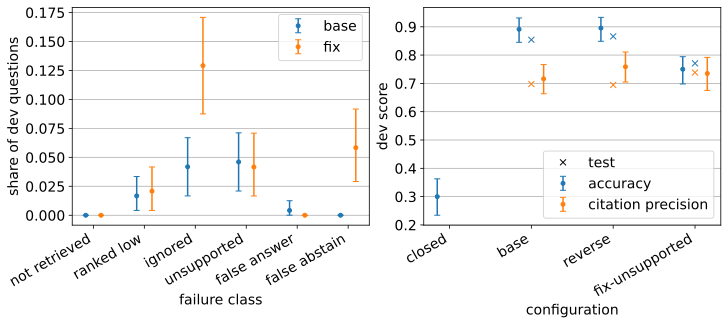

In [12]:
if FIX and ready('closed', 'base', FIX):
    d2l.use_svg_display()
    steps = ['closed', 'base'] + ([BEST] if BEST and BEST != FIX else []
                                  ) + [FIX]
    dev = {c: scores(c) for c in steps}
    test = {c: scores(c, 'test') for c in steps[1:] if ready(c, split='test')}
    series, waterfall, marks = {}, {}, {'test': ('x', {})}
    for name, df in (('base', BC), ('fix', after)):
        sh = class_shares(df.cls[df.cls != 'unjudged'])  # judged only
        series[name] = (sh.share, sh.lo, sh.hi)
    for m, label in (('accuracy', 'accuracy'),
                     ('cite_precision', 'citation precision')):
        est = [ci(dev[c][m], cluster=dev[c].cluster)[0] for c in steps]
        waterfall[label] = tuple(  # closed book cites nothing: no point
            [np.nan if r is None else f(r) for r in est]
            for f in (lambda r: r.mean, lambda r: r.ci[0],
                      lambda r: r.ci[1]))
        xs = [i for i, c in enumerate(steps) if c in test]
        marks['test'][1][label] = (xs, [test[steps[i]][m].mean()
                                        for i in xs])
    with d2l.plt.rc_context({'font.size': 14}):  # legible on a slide
        _, axes = d2l.plt.subplots(1, 2, figsize=(10, 4.4),
                                   layout='constrained')
        d2l.plot_intervals([c.replace('_', ' ') for c in CLASSES], series,
                           'failure class', 'share of dev questions',
                           axes=axes[0])
        d2l.plot_intervals(steps, waterfall, 'configuration', 'dev score',
                           axes=axes[1], marks=marks)

<!-- d2l:prose id=rag-failures-md-9 fw=all -->

Beyond these fixes lies a large literature that this section does not
measure, from transforming the query and retrieving again during generation
to retrieval learned with reinforcement learning, compressed contexts and
structured indexes (that section). Each of these methods
can be judged with the procedure of this section.

## Marginalizing over Retrieved Documents

A dense retriever is trained on pairs of a question and a relevant passage,
with a contrastive loss (that section). Nobody tells it
whether the generator can use the passages it finds. Could the answers
alone teach it that? Our pipeline cannot even ask, because it treats
retrieval as preprocessing: passages are chosen, concatenated and read. The
model that gave RAG its name [@Lewis.Perez.Piktus.ea.2020] treats the
retrieved document as a hidden variable instead, which makes the system a
probabilistic model whose query encoder and generator can be trained
together. This is the only proof in our two sections on RAG. It is short,
and its last line answers the question just asked.

Let $x$ be the question, $y = (y_1, \ldots, y_n)$ the answer and $z$ a
document. The retriever gives each document a score $s_z$ and the
probability $p(z \mid x) = \mathrm{softmax}(\mathbf{s})_z$, and the
generator reads one document at a time. *RAG-Sequence* draws one document
for the whole answer:

$$p_S(y \mid x) = \sum_z p(z \mid x) \prod_{t=1}^{n} p(y_t \mid x, z, y_{<t}).$$

*RAG-Token* may draw a new document for every token:

$$p_T(y \mid x) = \prod_{t=1}^{n} \sum_z p(z \mid x)\, p(y_t \mid x, z, y_{<t}).$$

RAG-Sequence asks which single document explains the answer; RAG-Token lets
each token be explained by whichever document supports it. For one document
the two coincide. The smallest case in which they differ has two documents
and two tokens. Let $p(z \mid x) = (0.6, 0.4)$, let document 1 give the two
tokens the probabilities 0.9 and 0.2, and document 2 give 0.1 and 0.8. Then

$$
\begin{aligned}
p_S &= 0.6 \cdot 0.9 \cdot 0.2 + 0.4 \cdot 0.1 \cdot 0.8 = 0.140,\\
p_T &= (0.6 \cdot 0.9 + 0.4 \cdot 0.1)(0.6 \cdot 0.2 + 0.4 \cdot 0.8) = 0.2552.
\end{aligned}
$$

Each document supports half of the answer, and only RAG-Token combines the
halves: the multi-passage question in its smallest form. Our pipeline
combines passages too, through attention over their concatenation, with one
long prompt instead of one short pass per document.

The sum over the corpus is too large, so it runs over the $k$ documents of
largest $p(z \mid x)$, the retrieved set $\mathcal{K}$. What does that drop?
Write $L_z = p(y \mid x, z)$, $p_S^{(k)}$ for the sum restricted to
$\mathcal{K}$, and $m_k = \sum_{z \in \mathcal{K}} p(z \mid x)$ for the
retriever's mass on $\mathcal{K}$. (Implementations usually renormalize
$p(z \mid x)$ over $\mathcal{K}$; Exercise 1 shows
that the bound below survives.) The dropped terms are nonnegative and each
$L_z$ is at most $\max_z L_z$, so

$$0 \le p_S - p_S^{(k)} = \sum_{z \notin \mathcal{K}} p(z \mid x)\, L_z \le (1 - m_k) \max_z L_z.$$

The truncation error is at most the probability mass that the retriever
puts outside the retrieved set, since no $L_z$ exceeds 1. A retriever with
peaked probabilities loses little; one that spreads its mass can lose much,
however good its ranking.

How does the generator teach the retriever? We differentiate the logarithm
of the equation with respect to a score.

**Proposition.** Let $p(z \mid x, y) = p(z \mid x) L_z / p_S(y \mid x)$ be
the posterior over documents once the answer is known. Then

$$\frac{\partial \log p_S(y \mid x)}{\partial s_z} = p(z \mid x, y) - p(z \mid x).$$

**Proof.** Write $\log p_S = \log \sum_{z'} e^{s_{z'}} L_{z'} - \log
\sum_{z'} e^{s_{z'}}$. The derivative of the first term with respect to
$s_z$ is $e^{s_z} L_z / \sum_{z'} e^{s_{z'}} L_{z'}$, the posterior; that of
the second is $e^{s_z} / \sum_{z'} e^{s_{z'}}$, the prior. $\blacksquare$

Let us read the result. Since the posterior is $p(z \mid x)\, L_z / p_S$,
the gradient is $p(z \mid x)(L_z / p_S - 1)$: a document's score rises
when it explains the answer better than the documents do on average,
weighted by the retriever's probabilities, and falls when it explains it
worse. No label says which document was relevant. That is a great deal to
learn from answers alone. But it is
learned through the generator's eyes. If the generator ignores every
document, $L_z$ is the same for all, the posterior equals the prior, and
the retriever learns nothing. If it ignores one relevant passage while
others explain the answer well, the ignored passage falls below the
average, and its score falls. So the answer to our question is a
qualified yes: the retriever learns which passages the generator uses,
and those are not always the relevant ones.

The form is general. Take any marginal likelihood over a latent choice $z$,
and differentiate its logarithm with respect to the parameters of
$p(z \mid x)$. The result is an expectation under the posterior,
$\nabla \log p(y \mid x) = \mathbb{E}_{p(z \mid x, y)}[\nabla \log p(z \mid x)]$,
the same posterior that the E-step of that section
computes. For a softmax prior it is posterior minus prior. The cell checks
the gradient against autograd, the bound for every $k$, the two
marginalizations for one and three documents, and the case by hand.

In [13]:
g = torch.Generator().manual_seed(0)
s = torch.randn(8, dtype=torch.float64, generator=g, requires_grad=True)
L = torch.rand(8, dtype=torch.float64, generator=g)  # p(y | x, z)
prior = s.softmax(0)  # the retriever's p(z | x)
torch.log((prior * L).sum()).backward()
post = (prior * L / (prior * L).sum()).detach()
err = (s.grad - (post - prior.detach())).abs().max().item()
print(f'gradient of log p(y | x) - (posterior - prior): {err:.1e}')
assert err < 1e-12
p, gaps = (prior * L).sum().item(), []
order = prior.argsort(descending=True)
for k in range(1, 9):  # p_S^(k): the k documents of largest prior
    top = order[:k]
    gap = p - (prior[top] * L[top]).sum().item()
    bound = (1 - prior[top].sum().item()) * L.max().item()
    assert -1e-15 <= gap <= bound + 1e-15
    gaps.append((k, gap, bound))
print(pd.DataFrame(gaps, columns=['k', 'p - p_k', 'bound']).round(4)
      .to_string(index=False))
s2 = s.detach().clone().requires_grad_()
torch.log((s2.softmax(0) * 0.3).sum()).backward()  # a constant likelihood
assert s2.grad.abs().max() < 1e-15

def p_seq_tok(pz, P):
    """RAG-Sequence and RAG-Token probabilities of an answer: pz the
    retriever's probabilities (D,), P the token probabilities (D, T)."""
    return (pz * P.prod(1)).sum().item(), (pz @ P).prod().item()

P3 = torch.rand(3, 3, dtype=torch.float64, generator=g)
pz3 = torch.rand(3, dtype=torch.float64, generator=g).softmax(0)
seq, tok_ = p_seq_tok(pz3, P3)
one = p_seq_tok(torch.ones(1, dtype=torch.float64), P3[:1])
assert abs(seq - tok_) > 1e-6 and abs(one[0] - one[1]) < 1e-15
print(f'three documents, three tokens: p_S {seq:.4f}, p_T {tok_:.4f}; '
      f'one document: both {one[0]:.4f}')
pz = torch.tensor([0.6, 0.4], dtype=torch.float64)  # the case by hand
P = torch.tensor([[0.9, 0.2], [0.1, 0.8]], dtype=torch.float64)
print('two documents, two tokens:\n  p_S = 0.6 * 0.9 * 0.2 + 0.4 * 0.1 * '
      '0.8 = {:.3f}\n  p_T = (0.6 * 0.9 + 0.4 * 0.1)(0.6 * 0.2 + 0.4 * 0.8) '
      '= {:.4f}'.format(*p_seq_tok(pz, P)))

gradient of log p(y | x) - (posterior - prior): 5.6e-17
 k  p - p_k  bound
 1   0.2218 0.3734
 2   0.1346 0.2504
 3   0.1079 0.1565
 4   0.0462 0.0768
 5   0.0278 0.0372
 6   0.0175 0.0192
 7   0.0044 0.0060
 8   0.0000 0.0000
three documents, three tokens: p_S 0.0586, p_T 0.0696; one document: both 0.0556
two documents, two tokens:
  p_S = 0.6 * 0.9 * 0.2 + 0.4 * 0.1 * 0.8 = 0.140
  p_T = (0.6 * 0.9 + 0.4 * 0.1)(0.6 * 0.2 + 0.4 * 0.8) = 0.2552


<!-- d2l:prose id=rag-failures-md-10 fw=all -->

The gradient matches posterior minus prior to rounding error, below
$10^{-16}$; every truncation error lies at or below its bound (at $k = 5$,
0.028 against 0.037); and the case by hand gives 0.140 and 0.2552.

## Cost and Long Context

Our pipeline concatenates instead of marginalizing, and every passage adds
prompt tokens that the generator must read. What does each stage cost in
time? The last cell reports the tokens and seconds per answer of each
configuration, then times retrieval and reranking one question at a time.

In [14]:
print(GENS[GENS.split == 'dev'].groupby('config', sort=False).agg(
    prompt_tokens=('n_prompt_tokens', 'mean'),
    new_tokens=('n_new_tokens', 'mean'),
    s_per_answer=('latency_s', 'mean')).round(2).to_string())
R = RET['sections']
qs = [q['question'] for q in DEV.subset(50 if GPU else 3, seed=1)]
depth = DEPTH if GPU else 5  # the CPU path reranks five chunks of one
R.search_batch(qs[:1], k=DEPTH)  # load the query encoder
t = time.time()
hits = [R.search(q, k=DEPTH) for q in qs]
t_ret = (time.time() - t) / len(qs)
pipe = d2l.RAGPipeline(R, None, None, rerank_k=depth)  # no generation
pipe._rerank(qs[:1], [[h.chunk_id for h in hits[0][:2]]])  # load it
rr = qs if GPU else qs[:1]
t = time.time()
pipe._rerank(rr, [[h.chunk_id for h in hs[:depth]] for hs in hits])
t_rr = (time.time() - t) / len(rr)
R.release()
print(f'one question at a time: retrieval {1000 * t_ret:.0f} ms '
      f'({len(qs)} questions), reranking {depth} chunks {1000 * t_rr:.0f} '
      f'ms ({len(rr)} questions)')

                 prompt_tokens  new_tokens  s_per_answer
config                                                  
base                   1936.88      110.86          1.19
base-repeat            1936.88      110.64          1.20
closed                   89.96      100.11          0.79
oracle                  629.67      101.57          0.90
budget-1500            1534.05      110.42          1.07
budget-6000            6346.02      114.77          2.55
fixed                  1840.05      107.33          1.28
fixed-over             2119.13      109.22          1.19
reverse                1936.88      111.47          1.14
rewrite-rerank         1923.96      112.68          1.91
fix-unsupported        1936.88      110.86          1.17


Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa


Qwen/Qwen3-Reranker-0.6B@e61197ed4502: Qwen3ForCausalLM, stop tokens [151645, 151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


one question at a time: retrieval 30 ms (50 questions), reranking 50 chunks 542 ms (50 questions)


<!-- d2l:prose id=rag-failures-md-11 fw=all -->

First-stage retrieval is cheap, about 30 ms per question. Reranking 50
chunks is not: about half a second, nearly half the time the generator
spends on a baseline answer. It is easy to forget that the reranker, a
model of 0.6 billion parameters, reads 50 pairs of question and chunk for
every question. The baseline does without it, and the stage experiment gave
no reason to add it.

The prompt is the context plus the instructions and the question, about
240 tokens more. Generation time barely moves between 1,500 and 2,100
prompt tokens, about 1.1 to 1.3 s per answer. At 6,300 tokens it doubles, to
2.6 s, partly because such long prompts run in batches of four instead of
eight. The rewrite with reranking takes about 1.9 s per answer, since the
generator first writes the query and the reranker then reads 50 chunks.

That leaves the question that longer context windows keep raising. If the
generator can read 6,000 tokens, why not whole chapters, and no retrieval at
all? On this set three times the baseline's context gained nothing
measurable, and the oracle of that section shows that the
generator, given only the right passages, still gets about one question in
fourteen wrong. More text does not cure a generator that ignores what it
already has. The agents of that section take a third path
and retrieve only when they decide that they need to. Whether whole chapters, at equal cost, would beat
retrieval on the questions that need several passages remains open.
Exercise 2 sets up the experiment.

## Summary

One accuracy number does not say what to fix in a retrieval-augmented
generator, and a favorite fix is a guess; this section let measurements
choose. Changing one stage at a time, with paired intervals on the same
questions, raised accuracy measurably nowhere: retrieval had no room, as the
share of hits predicted, and the generator did not read better for another
order or for more text. Fixed windows and a smaller budget lowered it.
Sorting the wrong answers by the first stage that lost them split them
mostly between answers that go beyond their passages and answers that miss
a fact their own context holds. The fix for the larger class, written down
in advance, checks each sentence against its citations. It lowered
accuracy by 0.14 on `dev` and 0.08 on `test`, by removing sentences that
carried the answer, among them uncited ones that the check never read: a
change aimed at one class can create others. The original RAG model marginalizes over
retrieved documents, and its retriever learns the posterior minus the
prior: the passages the generator uses, which are not always the ones that
are relevant. Whether whole chapters in a long context can replace
retrieval remains open.

## Exercises

1. **The truncation error and recall.** Start from the equation.
    1. Show that the bound is tight: give scores and likelihoods for which
       $p_S - p_S^{(k)} = (1 - m_k) \max_z L_z$.
    1. Suppose exactly one document $z^*$ answers each question, and the
       retriever is calibrated: $p(z \mid x)$ is the probability that $z$ is
       $z^*$. Show that the expectation of $1 - m_k$ over questions equals
       the probability that $z^*$ is not in the top $k$, one minus
       Recall@$k$.
    1. The baseline's five chunks hold a relevant one for 213 of the 220
       answerable questions, so Recall@5 $\approx 0.97$. What would the
       bound promise for RAG-Sequence over five documents if the retriever
       were calibrated? Why is a softmax over BM25 or dense scores rarely
       calibrated in this sense, and how would you calibrate it on `train`?
    1. Implementations usually renormalize the retriever's probabilities
       over $\mathcal{K}$ and use $p_S^{(k)} / m_k$. Show that the error
       $p_S - p_S^{(k)} / m_k$ can take either sign, and that its absolute
       value obeys the same bound.

1. [extended] **Long context against retrieval.** ●● Put whole chapters into
   the prompt instead of five retrieved chunks.
    1. Budget the memory first. From the configuration of Qwen3.5-9B
       (8 full-attention layers of 32, 4 key-value heads of width 256,
       bf16), compute the bytes of cache per token and the cache at 32,000
       tokens, and check with `d2l.config_memory` whether such a prompt fits
       beside the weights on a 24 GB card. Compare with Qwen3-4B, whose 36
       layers all attend.
    1. For the 20 `multihop` `dev` questions, build contexts of about
       32,000 tokens from the documents of their gold spans, filled up with
       other documents of the book. Compare accuracy and seconds per answer
       with the baseline, with paired intervals.
    1. Which wins, at what cost, and can 20 questions in this many
       documents decide it?

1. **Two marginalizations.** Use the equation
   and the equation.
    1. Show that RAG-Sequence and RAG-Token give the same probability for an
       answer of one token, whatever the number of documents.
    1. Is $p_T \ge p_S$ always? Prove it, or give a counterexample with two
       documents and two tokens.
    1. Which kind of answer does each marginalization favor, and which of
       them can a greedy decoder evaluate one token at a time?

1. [code] **What the check removed.** The fix of the unsupported class
   drops every sentence that cites nothing and every cited sentence that
   its check rejects. Use the recorded answers in `GENS`; no generation and
   no judge are needed.
    1. For each of the 34 answerable `dev` questions that the fix lost,
       compare the baseline's answer with the fix's, sentence by sentence.
       How many lost only sentences that cited nothing?
    1. Which question types have the most uncited sentences in the
       baseline's answers? Why might a generator leave the sentence that
       states the answer uncited and cite the one that explains it?
    1. Write down, before running anything, a variant of the fix that
       keeps uncited sentences, and predict its effect. Why may its result
       not be read on `test`, and what would it take to believe it?

1. [code] **Splitting the fix.** The fix written down for the ignored
   class, which the rule did not pick here, changes three settings at once:
   `RAG_FIXES['ignored']`.
    1. Define three arms that each change one of them: the quoting prompt
       alone (`dict(d2l.RAG_BASE, prompt='quote')`), the order with the best
       passages at both ends alone, and room for 500 new tokens alone.
       Before you run them, predict which carries the loss.
    1. Generate the three arms on `dev`, judge them with the local judge, and
       report each paired difference with the baseline and each arm's
       failure classes. Without two GPUs for the judge, compare the
       abstentions on the unanswerable questions, which need no judge.
    1. Generate the bundle `fix-ignored` as well. Do the three effects add
       up to the bundle's? What does the answer say about writing a fix down
       in advance as a bundle, and why may these results not be read on
       `test`?

1. **Failure counts from two graders.** The labeler called 9 of the 26
   failures correct.
    1. From the table of rule against labeler printed in
       that section, recount the classes with those nine
       answers taken as correct. Does the largest class change?
    1. With the bootstrap of the failure cell, or with the normal
       approximation to a binomial share, compute an interval for the share
       of the largest class among the remaining failures. Can the classes
       now be ranked?
    1. What would it take to decide which grader is right on the nine, and
       why would asking a third model not settle it?

1. [code] **Coverage of the whole span.** Coverage counts a question as
   covered when its chunks hold half of a gold span.
    1. Write a variant of `d2l.cov_at_budget` that requires a whole gold
       span, and recompute the coverage of section chunks and fixed windows
       at 1,000, 2,000 and 3,000 tokens. (Without a GPU, use BM25 rankings
       for both.)
    1. Does the gap between windows and sections grow, and does it now come
       closer to the windows' loss in accuracy?
    1. Gold spans can cross a section boundary too. How often do they, and
       what would you change in the chunker?

1. [code] **A smaller generator.** Replace Qwen3.5-9B by Qwen3.5-4B of the
   same family and keep everything else fixed.
    1. Before you run it, predict which failure class grows most and whether
       the gain of the oracle context over the baseline becomes measurable.
    1. Regenerate the `base`, `closed` and `oracle` arms, judge them, and
       report the class shares with their intervals and the paired
       differences with the larger generator. Without two GPUs for the
       judge, compare what needs no judge: abstention rates, false
       abstentions and citation precision.